# Fit the narrow lines of SDSS J112611.63+425246.4
* Remove the stellar component
* Determine the refined redshift
* Create the narrow line template

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from scipy.ndimage import gaussian_filter1d
from copy import deepcopy

from astropy.modeling import models, fitting
import sys
sys.path.append('/Users/shangguan/Softwares/my_modules/SAGAN/')
import galspec
from extinction import ccm89, remove
import spectres

import temp_utils as tu

import matplotlib as mpl
mpl.rc("xtick", direction="in", labelsize=16)
mpl.rc("ytick", direction="in", labelsize=16)
mpl.rc("xtick.major", width=1., size=8)
mpl.rc("ytick.major", width=1., size=8)
mpl.rc("xtick.minor", width=1., size=5)
mpl.rc("ytick.minor", width=1., size=5)

# automatic reload the modules
%load_ext autoreload
%autoreload 2

ls_km = 2.99792e5 # km/s
wave_dict = galspec.utils.line_wave_dict
label_dict = galspec.utils.line_label_dict

label_bHa = tu.line_label_map['bHalpha']
label_bHb = tu.line_label_map['bHbeta']
label_bHg = tu.line_label_map['bHgamma']
label_aHa = tu.line_label_map['aHalpha']
label_aHb = tu.line_label_map['aHbeta']
label_aHg = tu.line_label_map['aHgamma']
label_bHeII = tu.line_label_map['bHeII']
label_bHeI = tu.line_label_map['bHeI']

resolving_power=1800

/Users/shangguan/Softwares/miniforge3/envs/norm/lib/python3.13/site-packages/spectres/spectral_resampling.py:104: RuntimeWarning: Spectres: new_wavs contains values outside the range in spec_wavs, new_fluxes and new_errs will be filled with the value set in the 'fill' keyword argument (by default 0).
  warnings.warn(


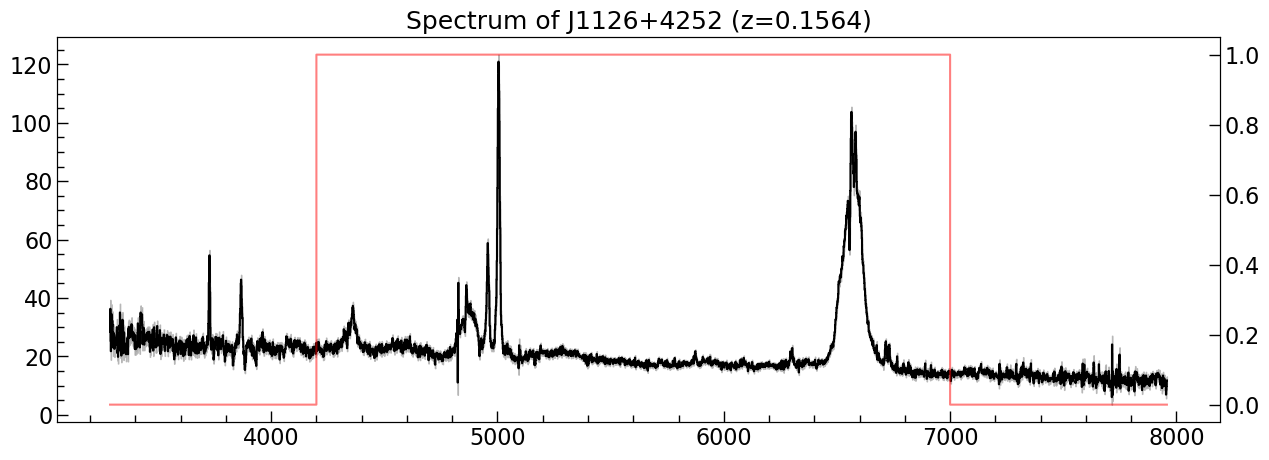

In [2]:
# get spectrum
tb = Table.read('../data_20251121/target_info.ipac', format='ipac')
loop = 4
targname = tb['Name'][loop]
Av = tb['Av'][loop]
zred = tb['zred'][loop]

# Read data
spec = np.loadtxt('results/J1126+4252_nostar.txt')
wave_use = spec[:, 0] / (1 + zred)
flux_use = spec[:, 1]
ferr_use = spec[:, 2]

wave_uni = np.linspace(wave_use.min(), wave_use.max(), len(wave_use))
flux_use, ferr_use = spectres.spectres(wave_uni, wave_use, flux_use, ferr_use)
fltr = ~np.isnan(flux_use) & ~np.isnan(ferr_use)
flux_use = flux_use[fltr]
ferr_use = ferr_use[fltr]
wave_use = wave_uni[fltr]


# Read the templates
temp_sii = np.loadtxt('results/J1126+4252_sii.txt')
velc_temp = temp_sii[:, 0]
flux_temp = temp_sii[:, 1]


# include the H-alpha, H-beta, and H-gamma line regions
weight_lines = np.zeros_like(wave_use)
line_windows = [(4200, 5400), (5400, 6100), (6100, 7000)]
for window in line_windows:
    weight_lines[(wave_use > window[0]) & (wave_use < window[1])] = 1

fig, ax = plt.subplots(figsize=(15, 5))
ax.step(wave_use, flux_use, color='k', where='mid', label='Flux')
ax.fill_between(wave_use, flux_use - ferr_use, flux_use + ferr_use, color='gray', alpha=0.5, step='mid', label='Error')
ax.minorticks_on()

#ax.axvline(4815, color='C3', ls='--', alpha=0.7)
#ax.axvline(4835, color='C3', ls='--', alpha=0.7)
#ax.set_xlim([6100, 7000])
#ax.set_ylim([0, 38])
#ax.set_xlim(4800, 5100)

axr = ax.twinx()
axr.step(wave_use, weight_lines, color='r', where='mid', alpha=0.5, label='Line Regions')
ax.set_title(f'Spectrum of {targname} (z={zred:.4f})', fontsize=18)
plt.show()

## Fit the lines
* The [S II] is strong. Use it to be the narrow line template.
    * Need two components for the [S II]

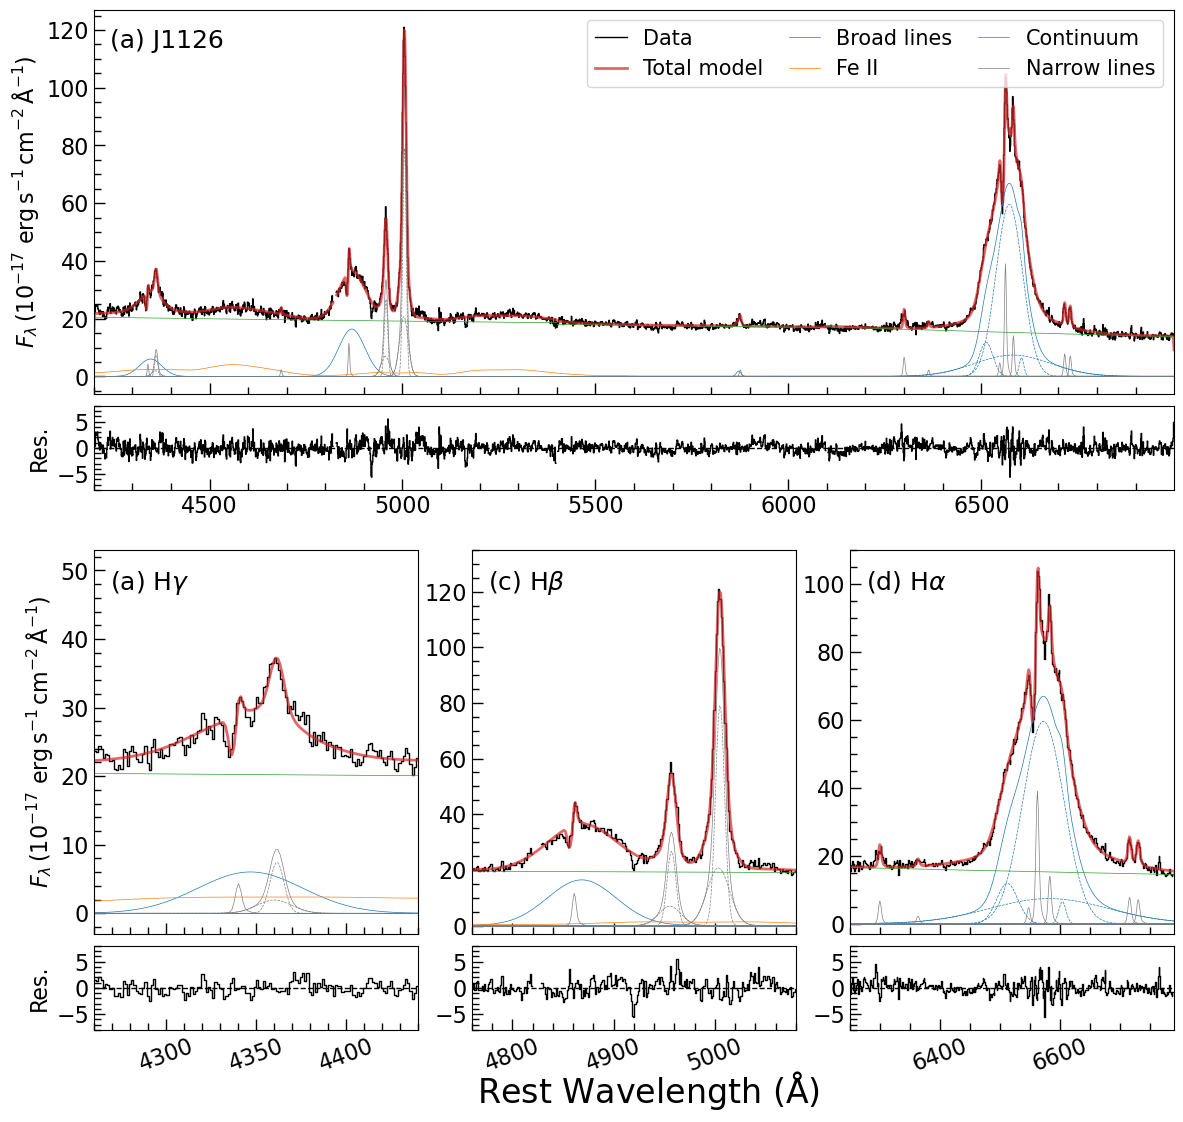

<Line_MultiGauss(amp_c=16.41816975, dv_c=450.45745732, sigma_c=2084.73044932, wavec=4861.333, name='Broad H$\\beta$')>
<Line_MultiGauss(amp_c=6.03490012, dv_c=450.45745732, sigma_c=2015.66730593, wavec=4340.471, name='Broad H$\\gamma$')>
<WindowedPowerLaw1D(amplitude=19.01343523, x_0=5100., alpha=0.39013767, x_min=4200., x_max=5400., name='Cont Hb')>
<Line_Absorption(logtau0=1.14691047, dv=-220.72255304, sigma=87.97131278, Cf=0.24808352, wavec=4861.333, name='Abs. H$\\beta$')>
<Line_Absorption(logtau0=0.67407404, dv=-220.72255304, sigma=87.97131278, Cf=0.24808352, wavec=4340.471, name='Abs. H$\\gamma$')>
<IronTemplate(amplitude=6.18365285, stddev=2867.00441366, z=0.003, name='Fe II')>
<Line_template(amplitude=11.6298969, dv=-7.19041083, wavec=4861.333, name='nHbeta')>
<Line_MultiGauss(amp_c=79.60466738, dv_c=-100.46941389, sigma_c=266.67602373, wavec=5006.843, amp_w0=0.26031869, dv_w0=-98.77683048, sigma_w0=661.3484678, name='OIII_5007_w')>
<Line_MultiGauss(amp_c=26.71297563, dv_c=-100

In [7]:
#################################################################################
# Fit Halpha + Hbeta + Hgamma
weight_lines = np.zeros_like(wave_use)
xlim = [wave_use.max(), wave_use.min()]
for window in line_windows:
    weight_lines[(wave_use > window[0]) & (wave_use < window[1])] = 1
    xlim[0] = min(xlim[0], window[0])
    xlim[1] = max(xlim[1], window[1])
weight_lines[(wave_use > 5398) & (wave_use < 5403)] = 0
weight_lines[(wave_use > 6097) & (wave_use < 6103)] = 0

for w0, w1 in tu.spec_masks['J1126']:
    weight_lines[(wave_use > w0) & (wave_use < w1)] = 0  # Mask some back pixels

#ferr_use[(wave_use > 4600) & (wave_use < 4750)] = np.inf
#ferr_use[(wave_use > 4815) & (wave_use < 4835)] = np.inf
#ferr_use[(wave_use > 4913) & (wave_use < 4930)] = np.inf
#weight_lines[~np.isfinite(ferr_use)] = 0  # Mask the He II 4686 region

# Fit Halpha
cont_ha = galspec.WindowedPowerLaw1D(amplitude=15.40820386, x_0=6550., alpha=1.62089904,
                                   x_min=line_windows[2][0], x_max=line_windows[2][1], name=f"Cont Ha")

bha = galspec.Line_MultiGauss(n_components=4, amp_c=60.44651836, dv_c=495.04068819, sigma_c=1567.33232168, 
                            amp_w0=0.11515663, dv_w0=398.57810918, sigma_w0=4635.59919029, 
                            amp_w1=0.21008941, dv_w1=-2745.71084697, sigma_w1=836.11863815, 
                            amp_w2=0.07554253, dv_w2=1438.51185246, sigma_w2=239.4887685,
                            wavec=wave_dict['Halpha'], name=label_bHa)
nha = galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=38.73992454, dv=-3.08926602, 
                          wavec=wave_dict['Halpha'], name='nHalpha')
nn2 = galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=13.0277327, dv=-3.08926602, 
                          wavec=wave_dict['NII_6583'], name='NII_6583') +\
      galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=4.40126105, dv=-3.08926602, 
                         wavec=wave_dict['NII_6548'], name='NII_6548')
ns2 = galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=7.68717741, dv=-3.08926602, 
                          wavec=wave_dict['SII_6716'], name='SII_6716') +\
      galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=7.34043994, dv=-3.08926602, 
                         wavec=wave_dict['SII_6731'], name='SII_6731')
no1 = galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=6.2490847, dv=-3.08926602,
                          wavec=wave_dict['OI_6300'], name='OI_6300') +\
      galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=2.08302823, dv=-3.08926602,
                          wavec=wave_dict['OI_6364'], name='OI_6364')

aha = galspec.Line_Absorption(logtau0=1.91914629, dv=-221.72004549, sigma=90.09610263, Cf=0.23781811, wavec=wave_dict['Halpha'], name=label_aHa)
aha.sigma.bounds = (5, 300)

b_lines = (bha + cont_ha) * aha
b_lines = galspec.convolve_lsf(b_lines, wavec=bha.wavec, resolving_power=resolving_power)
n_lines = nha + nn2 + ns2 + no1
m_fit_ha = b_lines + n_lines
m_fit_ha['NII_6548'].amplitude.tied = galspec.tie_template_amplitude('NII_6583', ratio=2.96)
m_fit_ha['OI_6364'].amplitude.tied = galspec.tie_template_amplitude('OI_6300', ratio=3.0)

for ln in ['NII_6583', 'NII_6548', 'SII_6716', 'SII_6731', 'OI_6300', 'OI_6364']:  #
    m_fit_ha[ln].dv.tied = galspec.tie_template_dv('nHalpha')


#################################################################################
# He I 5876
cont_he1 = galspec.WindowedPowerLaw1D(amplitude=17.58485499, x_0=5750., alpha=0.45570265, 
                                   x_min=line_windows[1][0], x_max=line_windows[1][1], name=f"Cont HeI")
bhe1 = galspec.Line_MultiGauss(n_components=1, amp_c=1.84864655, dv_c=-225.50115712, sigma_c=304.69869347, 
                             wavec=wave_dict['HeI_5876'], name=label_bHeI)
nhe1 = galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=2.30047157, dv=-6.98691604, 
                           wavec=wave_dict['HeI_5876'], name='nHeI_5876')
m_fit_he1 = cont_he1 + bhe1 + nhe1


#################################################################################
# Hbeta
cont = galspec.WindowedPowerLaw1D(amplitude=19.40826533, x_0=5100., alpha=0.4510835,
                                x_min=line_windows[0][0], x_max=line_windows[0][1], name=f'Cont Hb')
iron = galspec.IronTemplate(amplitude=4.72987889, stddev=961.22811943, z=0.00, name='Fe II', 
                          fixed=dict(amplitude=False, z=False, stddev=False))

bhb = galspec.Line_MultiGauss(n_components=1, amp_c=16.68656141, dv_c=495.04068819, sigma_c=1945.84293971, 
                            wavec=wave_dict['Hbeta'], name=label_bHb)
nhb = galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=11.21171095, dv=-3.08926602,
                          wavec=wave_dict['Hbeta'], name='nHbeta')
#no3 = galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=10.19914848, dv=-14.8562894, 
#                          wavec=wave_dict['OIII_5007'], name='OIII_5007') +\
#      galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=3.42253305, dv=-14.8562894, 
#                         wavec=wave_dict['OIII_4959'], name='OIII_4959')
no3_w = galspec.Line_MultiGauss(n_components=2, amp_c=78.78573626, dv_c=-92.89979716, sigma_c=272.3449088, 
                              amp_w0=0.26807, dv_w0=-138.86743727, sigma_w0=650.45247105, 
                              wavec=wave_dict['OIII_5007'], name='OIII_5007_w') +\
        galspec.Line_MultiGauss(n_components=2, amp_c=26.43816653, dv_c=-92.89979716, sigma_c=272.3449088, 
                              amp_w0=0.26807, dv_w0=-138.86743727, sigma_w0=650.45247105,
                              wavec=wave_dict['OIII_4959'], name='OIII_4959_w')
ahb = galspec.Line_Absorption(logtau0=1.06605676, dv=-221.72004549, sigma=90.09610263, Cf=0.23781811, wavec=wave_dict['Hbeta'], name=label_aHb)
ahb.sigma.bounds = (5, 300)

# He II 4686
nhe2 = galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=1.8045785, dv=-6.98691604, 
                           wavec=wave_dict['HeII_4686'], name='nHeII_4686')
#bhe2 = galspec.Line_MultiGauss(n_components=1, amp_c=2.27815954, dv_c=-332.02455588, sigma_c=1869.43745362, 
#                             wavec=wave_dict['HeII_4686'], name=label_bHeII)

# Hgamma
bhg = galspec.Line_MultiGauss(n_components=1, amp_c=5.70179414, dv_c=495.04068819, sigma_c=1910.610973, 
                            wavec=wave_dict['Hgamma'], name=label_bHg)
nhg = galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=5.70735316, dv=-3.08926602, 
                          wavec=wave_dict['Hgamma'], name='nHgamma')
#no3_4360 = galspec.Line_template(template_velc=velc_temp, template_flux=flux_temp, amplitude=0., dv=-14.8562894, 
#                               wavec=wave_dict['OIII_4363'], name='OIII_4363')
no3_4360_w = galspec.Line_MultiGauss(n_components=2, amp_c=8.11946906, dv_c=-92.89979716, sigma_c=272.3449088, 
                                   amp_w0=0.26807, dv_w0=-138.86743727, sigma_w0=650.45247105,
                                   wavec=wave_dict['OIII_4363'], name='OIII_4363_w')
ahg = galspec.Line_Absorption(logtau0=0.59322034, dv=-221.72004549, sigma=90.09610263, Cf=0.23781811, wavec=wave_dict['Hgamma'], name=label_aHg)
ahg.sigma.bounds = (5, 300)

b_lines = (bhb + bhg + cont) * ahb * ahg  #+ bhe2
b_lines = galspec.convolve_lsf(b_lines, wavec=bhb.wavec, resolving_power=resolving_power)
m_init = b_lines + iron + nhb + no3_w + nhe2 + nhg + no3_4360_w + m_fit_ha + m_fit_he1

m_init['OIII_4959_w'].amp_c.tied = galspec.tie_MultiGauss_amp_c('OIII_5007_w', ratio=2.98)

for ln in ['nHbeta', 'nHgamma', 'nHeI_5876', 'nHeII_4686']: #, 'OIII_5007', 'OIII_4959', 'OIII_4363'
    m_init[ln].dv.tied = galspec.tie_template_dv('nHalpha')

m_init[label_aHb].dv.tied = galspec.tie_Absorption_dv(label_aHa)
m_init[label_aHb].sigma.tied = galspec.tie_Absorption_sigma(label_aHa)
m_init[label_aHg].dv.tied = galspec.tie_Absorption_dv(label_aHa)
m_init[label_aHg].sigma.tied = galspec.tie_Absorption_sigma(label_aHa)
m_init[label_aHb].Cf.tied = galspec.tie_Absorption_Cf(label_aHa)
m_init[label_aHg].Cf.tied = galspec.tie_Absorption_Cf(label_aHa)
m_init[label_aHb].logtau0.tied = galspec.tie_Absorption_logtau0(label_aHa, ratio=7.13)
m_init[label_aHg].logtau0.tied = galspec.tie_Absorption_logtau0(label_aHa, ratio=21.18)
m_init[label_aHa].logtau0.bounds = (-2, 2)

m_init[label_bHb].dv_c.tied = galspec.tie_MultiGauss_dv_c(label_bHa)
m_init[label_bHg].dv_c.tied = galspec.tie_MultiGauss_dv_c(label_bHa)

m_init['OIII_4959_w'].dv_c.tied = galspec.tie_MultiGauss_dv_c('OIII_5007_w')
m_init['OIII_4959_w'].sigma_c.tied = galspec.tie_MultiGauss_sigma_c('OIII_5007_w')
m_init['OIII_4959_w'].amp_w0.tied = galspec.tie_MultiGauss_amp_w0('OIII_5007_w')
m_init['OIII_4959_w'].dv_w0.tied = galspec.tie_MultiGauss_dv_w0('OIII_5007_w')
m_init['OIII_4959_w'].sigma_w0.tied = galspec.tie_MultiGauss_sigma_w0('OIII_5007_w')
m_init['OIII_4363_w'].dv_c.tied = galspec.tie_MultiGauss_dv_c('OIII_5007_w')
m_init['OIII_4363_w'].sigma_c.tied = galspec.tie_MultiGauss_sigma_c('OIII_5007_w')
m_init['OIII_4363_w'].amp_w0.tied = galspec.tie_MultiGauss_amp_w0('OIII_5007_w')
m_init['OIII_4363_w'].dv_w0.tied = galspec.tie_MultiGauss_dv_w0('OIII_5007_w')
m_init['OIII_4363_w'].sigma_w0.tied = galspec.tie_MultiGauss_sigma_w0('OIII_5007_w')

fwhm_ha = galspec.line_emission_fwhm(m_init, [label_bHa], wave_use, wave_dict['Halpha'])
m_init['Fe II'].amplitude.bounds = (0, None)
m_init['Fe II'].stddev = fwhm_ha/2.3548
m_init['Fe II'].stddev.bounds = (fwhm_ha/2.3548/1.5, fwhm_ha/2.3548*1.5)
m_init['Fe II'].z.bounds = (-0.003, 0.003)

fitter = fitting.LevMarLSQFitter()
m_fit_hb = fitter(m_init, wave_use, flux_use, weights=weight_lines, maxiter=10000)

tu.plot_all_4p_J1126(wave_use, flux_use, m_fit_hb, weight=weight_lines)
#plt.savefig('results/figs/J1126+4252_4p_levmar.pdf', bbox_inches='tight')
plt.show()

for m in m_fit_hb:
    print(m.__repr__())

In [8]:
##################################################################################
print('Running MCMC with all parameters varying...')
mcmc = tu.run_mcmc_all(m_init, wave_use, flux_use, ferr_use, weight_lines, 
                       nwalkers=200, nsteps=100, nburn=50, fit=False)
mcmc.fit()

Running MCMC with all parameters varying...
MCMC_Fit initialized with 49 free parameters.


100%|██████████| 100/100 [00:25<00:00,  3.98it/s]


(array([[  16.68849336, 1945.832859  ,    5.76207018, ..., -225.52229077,
          304.71736833,    2.31853873],
        [  16.67246051, 1945.84484399,    5.70815174, ..., -225.51071003,
          304.69762113,    2.29567735],
        [  16.67303516, 1945.84420272,    5.67727438, ..., -225.5171358 ,
          304.74748886,    2.34077512],
        ...,
        [  16.70796109, 1945.74486018,    5.76661382, ..., -225.3561769 ,
          304.71501791,    2.31112972],
        [  16.6793511 , 1945.784402  ,    5.64721335, ..., -225.54265811,
          304.6777852 ,    2.38072627],
        [  16.64136182, 1945.83152935,    5.74795652, ..., -225.5420542 ,
          304.76344953,    2.30234164]]),
 <CompoundModel(amp_c_0=16.68319155, dv_c_0=495.14391652, sigma_c_0=1945.76020001, wavec_0=4861.333, amp_c_1=5.75776336, dv_c_1=495.14391652, sigma_c_1=1910.54165141, wavec_1=4340.471, amplitude_2=19.45297943, x_0_2=5100., alpha_2=0.40795862, x_min_2=4200., x_max_2=5400., logtau0_3=0.89714993, dv_3=-

### Run MCMC sampling

In [5]:
mcmc = tu.run_mcmc_all(m_fit_hb, wave_use, flux_use, ferr_use, line_windows, 
                       nwalkers=200, nsteps=10000, nburn=5000, fit=True)
mcmc.check_convergence()
#mcmc.save_samples('results/samples/J1126+4252_samples.npz')
#galspec.save_mcmc(mcmc, 'results/models/galspec-model-J1126+4252.pkl')

#for loop in range(100):
#    print(mcmc.log_probability(mcmc.pos[loop, :]))
#    

MCMC_Fit initialized with 42 free parameters.


  0%|          | 0/10000 [00:00<?, ?it/s]/Users/shangguan/Softwares/miniforge3/envs/norm/lib/python3.13/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
  0%|          | 32/10000 [00:05<33:33,  4.95it/s]Traceback (most recent call last):
  File "/Users/shangguan/Softwares/miniforge3/envs/norm/lib/python3.13/site-packages/emcee/ensemble.py", line 640, in __call__
    return self.f(x, *self.args, **self.kwargs)
           ~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/shangguan/Softwares/my_modules/SAGAN/sagan/mcmc_fit.py", line 262, in log_probability
    return lp + self.log_likelihood(theta)
                ~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/Users/shangguan/Softwares/my_modules/SAGAN/sagan/mcmc_fit.py", line 238, in log_likelihood
    model_flux = model(self.wave_use)
  File "/Users/shangguan/Softwares/miniforge3/envs/norm/lib/python3.13/site-packages/astropy/modeling/core.py", line 112

emcee: Exception while calling your likelihood function:
  params: [ 1.63974268e+01  2.01630456e+03  5.96105862e+00  1.79370039e+03
  1.94878573e+01  4.65418045e-01  4.62932592e+00  9.09070334e+02
  3.26100093e-03  1.16537756e+01  7.96730053e+01 -9.93090953e+01
  2.67103986e+02  2.69381121e-01 -1.14597375e+02  6.58381418e+02
  4.41197228e+00  7.73895732e+00  5.79614171e+01  5.78112019e+02
  1.48260176e+03  1.32982740e-01  4.24255163e+02  4.25052645e+03
  2.69857324e-01 -2.63232815e+03  1.00296048e+03  9.02018124e-02
  1.33417265e+03  2.51252668e+02  1.55514505e+01  1.64762645e+00
  1.99819230e+00 -2.16064010e+02  8.75373138e+01  2.23523010e-01
  4.00103906e+01 -5.13571812e+00  1.36501702e+01  7.66885877e+00
  7.09324456e+00  6.68700244e+00]
  args: []
  kwargs: {}
  exception:


KeyboardInterrupt: 

### Load the MCMC fitting
* Save the best-fit model figure
* Save the decomposed absorption line figure

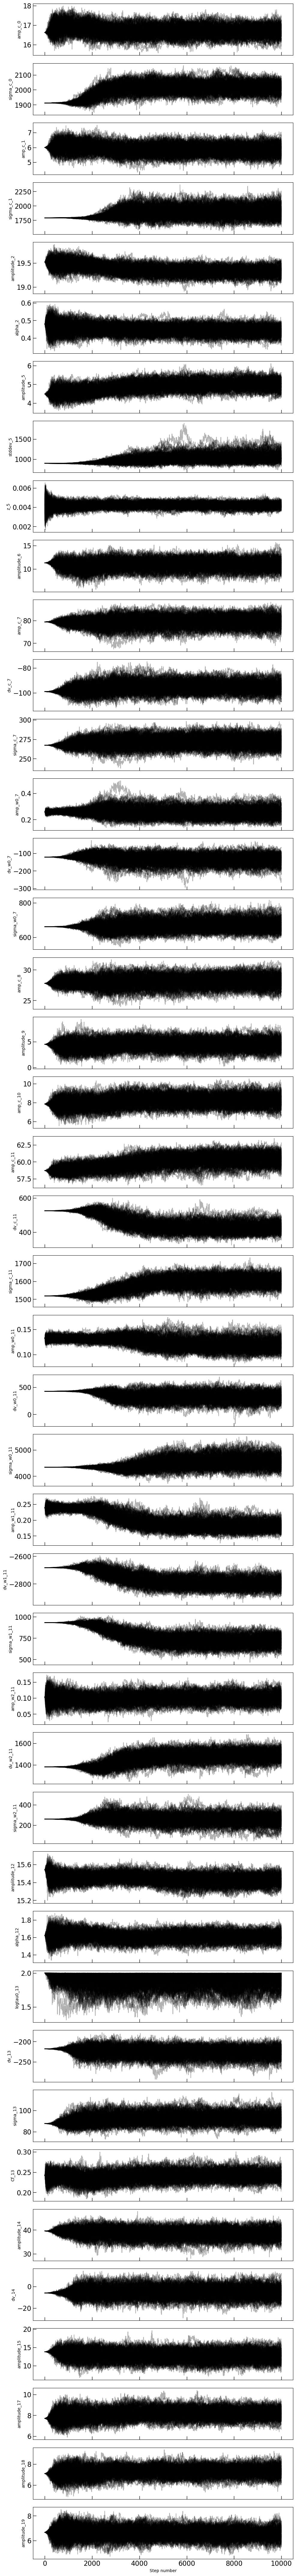

In [20]:
mcmc.plot_chain()
plt.show()

MCMC_Fit initialized with 43 free parameters.


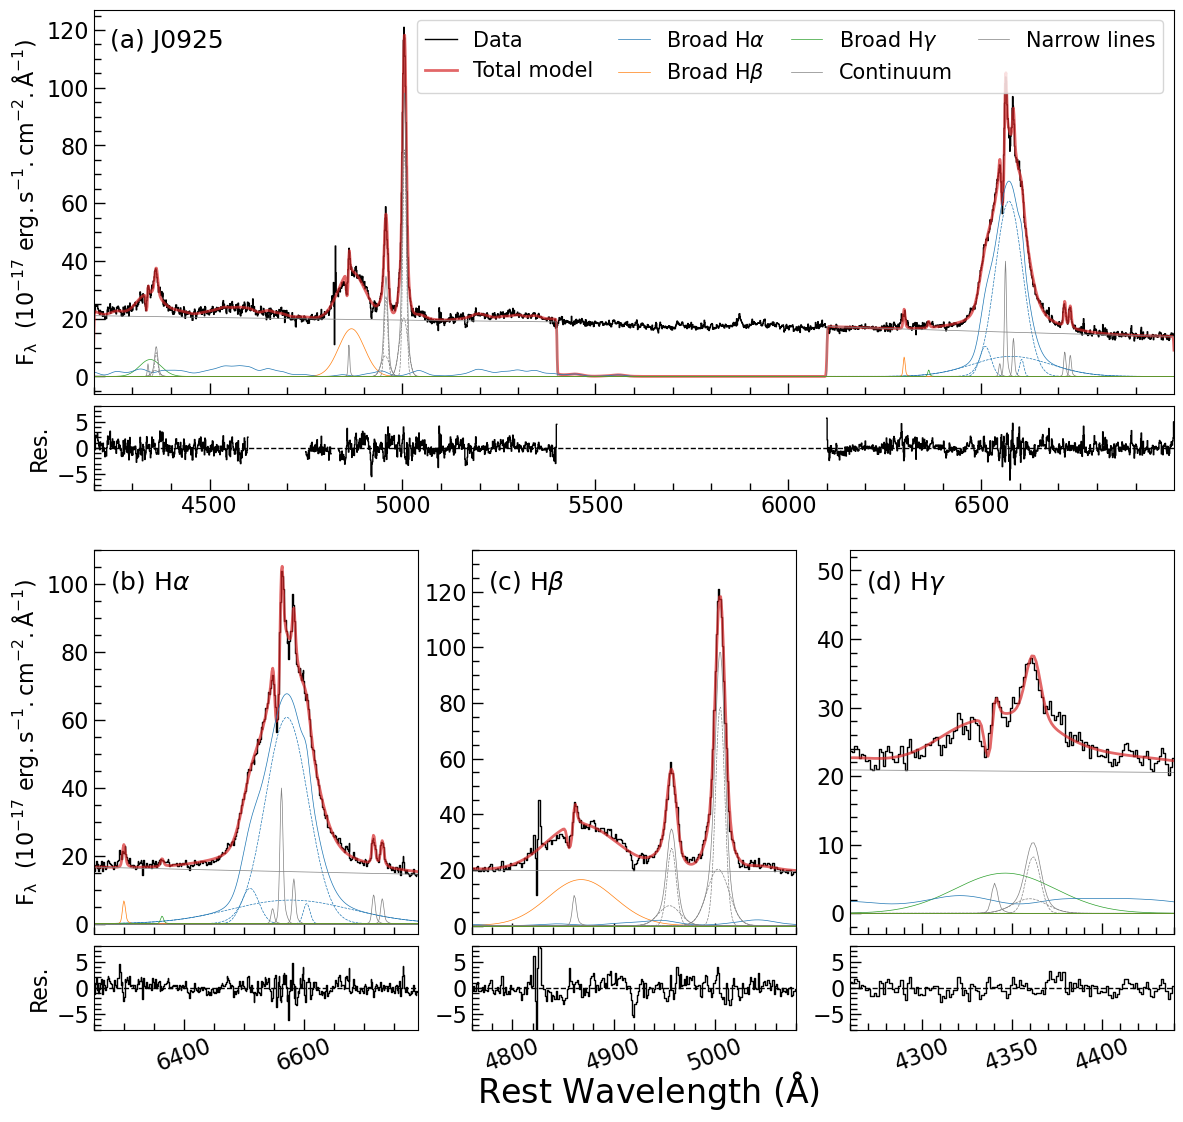

/Users/shangguan/Dropbox/Products/Latex/Absorption_selection/work/fitting_nb/temp_utils.py:415: RuntimeWarning: divide by zero encountered in divide
  flux_normalized = flux_decompose / flux_model
/Users/shangguan/Dropbox/Products/Latex/Absorption_selection/work/fitting_nb/temp_utils.py:415: RuntimeWarning: overflow encountered in divide
  flux_normalized = flux_decompose / flux_model


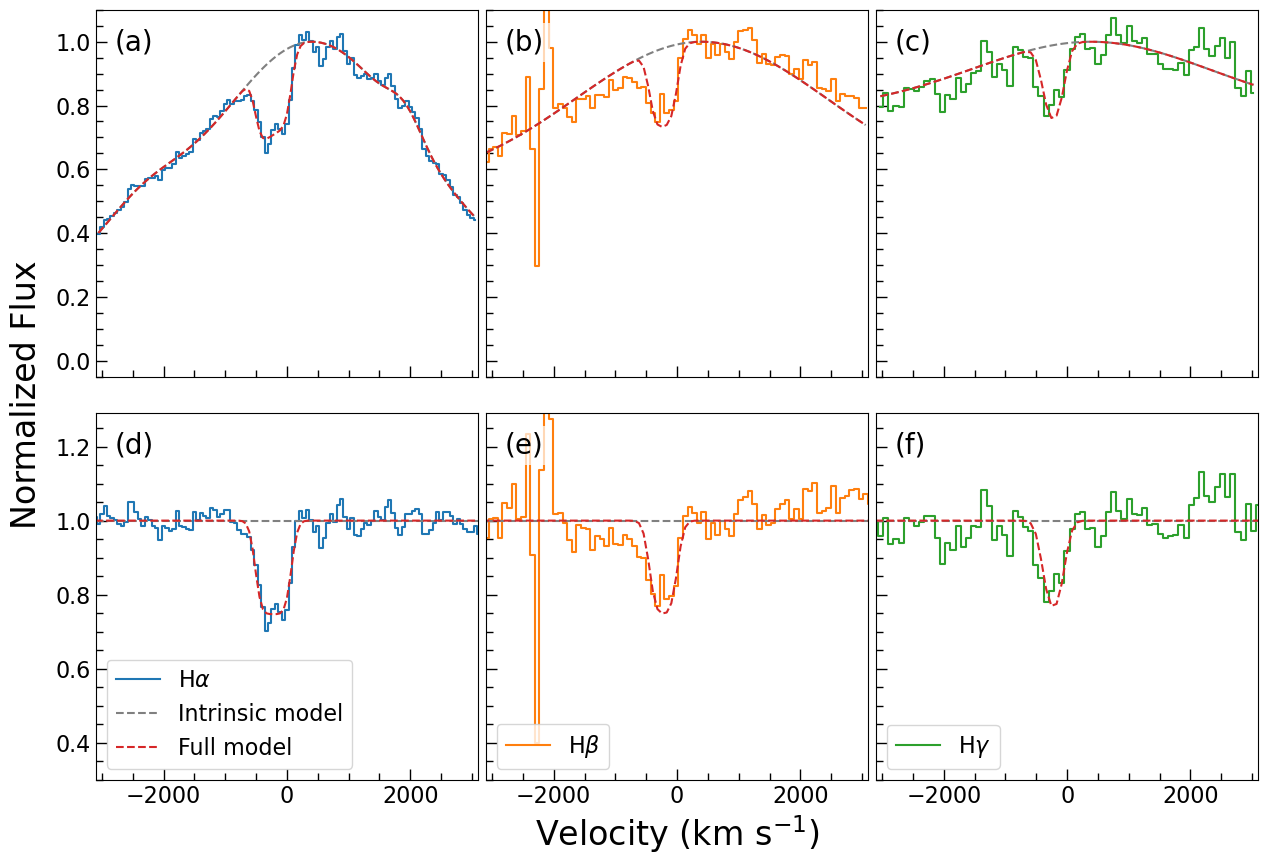

<Line_MultiGauss_None_GaussConv1D(amp_c=16.51856534, dv_c=405.65739893, sigma_c=2042.69847816, wavec=4861.333, name='Broad H$\\beta$')>
<Line_MultiGauss_None_GaussConv1D(amp_c=5.86229263, dv_c=405.65739893, sigma_c=1930.77553105, wavec=4340.471, name='Broad H$\\gamma$')>
<WindowedPowerLaw1D(amplitude=19.35178559, x_0=5100., alpha=0.43138375, x_min=4200., x_max=5400., name='Cont Hb')>
<Line_Absorption(logtau0=1.11476469, dv=-221.29645953, sigma=93.29566707, Cf=0.25259642, wavec=4861.333, name='Abs. H$\\beta$')>
<Line_Absorption(logtau0=0.64192826, dv=-221.29645953, sigma=93.29566707, Cf=0.25259642, wavec=4340.471, name='Abs. H$\\gamma$')>
<IronTemplate(amplitude=5.02571115, stddev=1037.10218593, z=0.00437881, name='Fe II')>
<Line_template(amplitude=10.95589661, dv=-3.28660792, wavec=4861.333, name='nHbeta')>
<Line_MultiGauss(amp_c=78.9460707, dv_c=-92.31166182, sigma_c=274.05243937, wavec=5006.843, amp_w0=0.25672266, dv_w0=-128.33028891, sigma_w0=645.63373738, name='OIII_5007_w')>
<Line

In [21]:
mcmc = tu.run_mcmc_all(m_fit_hb, wave_use, flux_use, ferr_use, line_windows, fit=False)
mcmc.load_samples('results/samples/J1126+4252_samples.npz')
m_fit, _, _ = mcmc.get_best_fit()

tu.plot_all_4p_J1126(wave_use, flux_use, m_fit, weight=weight_lines)
#plt.savefig('figs/J1126+4252_4p.pdf', bbox_inches='tight')
plt.show()

cont_models = ['Cont Ha', 'Cont Hb']
balmer_em_models = [label_bHa, label_bHb, label_bHg]
balmer_abs_models = [[label_aHa], [label_aHb], [label_aHg]]
line_names = ['Halpha', 'Hbeta', 'Hgamma']

tu.plot_decomposed_balmer(wave_use, flux_use, m_fit, cont_models, balmer_abs_models, 
                          balmer_em_models, line_names, xlim=[-3100, 3100])
#plt.savefig('figs/J1126+4252_balmer.pdf', bbox_inches='tight')
plt.show()

#tu.plot_all_4p_J1126(wave_use, flux_use, m_fit2, weight=weight_lines)
#plt.show()

for m in m_fit:
    print(m.__repr__())

In [ ]:
res = tu.measure_phys(mcmc, mcmc, wave_use, zred, nsamples=5000, cont_names=['Cont Ha', 'Cont Hb'])
tb = tu.table_phys(res)

fltr = tb['Parameter'] == f'logtau0_abs_Ha'
logtau0_abs_Ha = tb['Value'][fltr][0]
elogtau0_abs_Ha = tb['Error'][fltr][0]

if elogtau0_abs_Ha < 0:
    fltr = tb['Parameter'] == f'logtau0_abs_Hb'
    tb['Value'][fltr] = logtau0_abs_Ha - np.log10(7.13)
    tb['Error'][fltr] = elogtau0_abs_Ha

    fltr = tb['Parameter'] == f'logtau0_abs_Hg'
    tb['Value'][fltr] = logtau0_abs_Ha - np.log10(21.18)
    tb['Error'][fltr] = elogtau0_abs_Ha

tb.write('results/samples/J1126+4252_phys_table.ipac', format='ipac', overwrite=True)


tb.show_in_notebook()

         interactive tables it is recommended to use dedicated tools like:
         - https://github.com/bloomberg/ipydatagrid
         - https://docs.bokeh.org/en/latest/docs/user_guide/interaction/widgets.html#datatable
         - https://dash.plotly.com/datatable [warnings]


idx,Parameter,Value,Error
0,Flux_broad_Ha,7607.62241550077,49.807687889950714
1,Flux_narrow_Ha,279.9176337161457,14.779980020063492
2,FWHM_broad_Ha,4500.814662186787,49.104128027606635
3,EW_abs_Ha,3.0687486992823727,0.16861164943810164
4,Cf_abs_Ha,0.24194059452385827,0.011337631180238134
5,logtau0_abs_Ha,1.5645791118576429,-2.0
6,dv_abs_Ha,-226.41457011784877,11.710203668301018
7,sigma_abs_Ha,92.86466686007435,4.429048173283436
8,EW_em_Ha,494.6903046167806,4.630317412799179
9,Flux_broad_Hb,1367.0281239982141,21.538814886053437


In [ ]:
mcmc.plot_corner(thin=100)
plt.show()

<Line_MultiGauss(amp_c=13.74887486, dv_c=-117.2240081, sigma_c=398.26750779, wavec=4861.333, amp_w0=0.33487254, dv_w0=39.33447322, sigma_w0=1068.56409819, name='Broad H$\\beta$')>
<Line_MultiGauss(amp_c=5.46844552, dv_c=-117.2240081, sigma_c=505.44722172, wavec=4340.471, name='Broad H$\\gamma$')>
<WindowedPowerLaw1D(amplitude=12.3560113, x_0=5100., alpha=1.14622816, x_min=4200., x_max=5400., name='Cont Hb')>
<Line_Absorption(tau_0=5.87137684, dv=-141.86140147, sigma=49.71824844, Cf=0.37824965, wavec=4861.333, name='Abs. H$\\beta$')>
<Line_Absorption(tau_0=1.97653054, dv=-141.86140147, sigma=49.71824844, Cf=0.37824965, wavec=4340.471, name='Abs. H$\\gamma$')>
<IronTemplate(amplitude=0., stddev=1000., z=0., name='Fe II')>
<Line_template(amplitude=8.67759413, dv=5.41512696, wavec=4861.333, name='nHbeta')>
<Line_template(amplitude=71.18733563, dv=5.41512696, wavec=5006.843, name='OIII_5007')>
<Line_template(amplitude=23.88836766, dv=5.41512696, wavec=4958.911, name='OIII_4959')>
<Line_Mult